# Logistic Regression

`p = 1 / (1+e^-z)`

- `z` - linear combination (`m * x + b`)
- `p` - probability that the input belongs on the `positive` side (between 0 and 1)
- `e` - Euler's number (~2.718), a constant (this produces a the S-shape curve)


- `p` is above threshold (0.5), the mdoel predicts positive class

- coefficient - `m = 1`
- intercept - `b = -5`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 2D array

# hours of study(16,1)
X = np.array([[1], [2], [3], [4], [4], [5], [5], [6], [6], [7], [7], [8], [8], [9], [9], [10]])

# pass / fail = 0
y = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

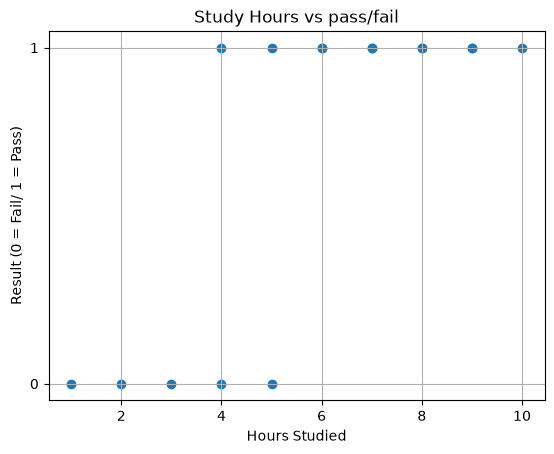

In [3]:
df = pd.DataFrame({'Hours_Studied': X.flatten(), 'Result':y})

plt.scatter(df['Hours_Studied'], df['Result'])
plt.title('Study Hours vs pass/fail')
plt.xlabel('Hours Studied')
plt.ylabel('Result (0 = Fail/ 1 = Pass)')
plt.yticks([0,1])
plt.grid(True)

In [4]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [6]:
model.predict([[4.5]])

array([1])

In [7]:
model.predict_proba([[4.5]])

array([[0.45931524, 0.54068476]])

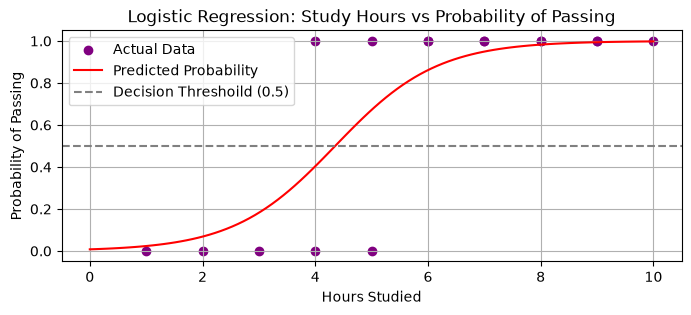

In [9]:
plt.figure(figsize=(8,3))
plt.scatter(X,y,color = 'purple', label='Actual Data')
x_line = np.linspace(0,10,100).reshape(-1,1)
y_line = model.predict_proba(x_line)[:,1]

plt.plot(x_line,y_line,color = 'red', label = 'Predicted Probability')

plt.axhline(0.5, color='gray', linestyle='--', label = 'Decision Threshoild (0.5)')

plt.title('Logistic Regression: Study Hours vs Probability of Passing')
plt.xlabel('Hours Studied')
plt.ylabel('Probability of Passing')
plt.legend()
plt.grid(True)

In [10]:
print('Coefficient (m):', model.coef_)
print('Intercept (b):', model.intercept_)

Coefficient (m): [[1.10923291]]
Intercept (b): [-4.82844844]


In [11]:
from sklearn.metrics import accuracy_score,precision_score,recall_score

In [14]:
y_pred = model.predict(X)
y_pred

array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [15]:
print('Accuracy:', accuracy_score(y,y_pred))
print('Precision', precision_score(y,y_pred))
print('Recall:', recall_score(y,y_pred))

Accuracy: 0.875
Precision 0.9090909090909091
Recall: 0.9090909090909091


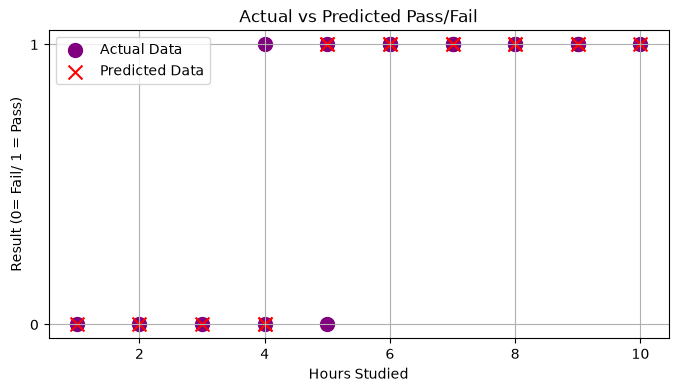

In [19]:
plt.figure(figsize=(8,4))
plt.scatter(X,y,color='purple', label = 'Actual Data', s=100)
plt.scatter(X,y_pred,color='red', label = 'Predicted Data', marker='x', s=100)
plt.title('Actual vs Predicted Pass/Fail')
plt.xlabel('Hours Studied')
plt.ylabel('Result (0= Fail/ 1 = Pass)')
plt.yticks([0,1])
plt.legend()
plt.grid(True)